In [1]:
import matplotlib.pyplot as plt
from umap import UMAP
from sklearn.preprocessing import StandardScaler

import seaborn as sns

import torch

In [2]:
x_input_vector = torch.load("../data/embeddings/X_input_vectors.pt").numpy()
y_target_labels = torch.load("../data/embeddings/y_target_labels.pt").numpy()

/home/nisanga/projects/huh-dna-specificity/.venv/lib/python3.12/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


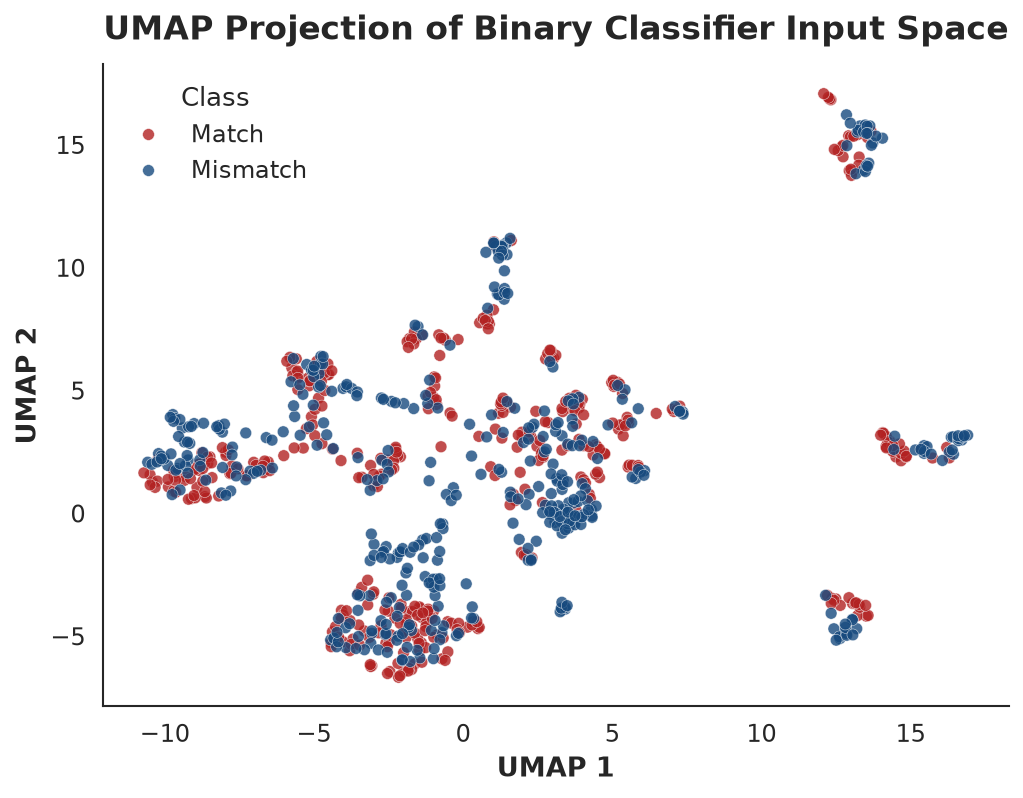

In [14]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from umap import UMAP

# Scale features
scaler = StandardScaler()
X_scaled = scaler.fit_transform(x_input_vector)

# Reduce dimensions
reducer = UMAP(n_neighbors=8, min_dist=0.5, random_state=42)
embedding = reducer.fit_transform(X_scaled)

label_names = {0: "Mismatch", 1: "Match"}

plot_data = pd.DataFrame({
    "UMAP 1": embedding[:, 0],
    "UMAP 2": embedding[:, 1],
    "Class": [label_names[int(label)] for label in y_target_labels],
})

sns.set_theme(
    style="white",
    context="paper",
    font_scale=1.3,
    rc={
        "axes.titleweight": "bold",
        "axes.labelweight": "bold",
    },
)

fig, ax = plt.subplots(figsize=(7, 5.5), dpi=150)

sns.scatterplot(
    data=plot_data,
    x="UMAP 1",
    y="UMAP 2",
    hue="Class",
    palette={"Mismatch": "#174A7E", "Match": "#B22222"},
    s=32,
    alpha=0.8,
    edgecolor="white",
    linewidth=0.25,
    ax=ax,
)

ax.set_title("UMAP Projection of Binary Classifier Input Space", pad=12, fontsize=16)
ax.set_xlabel("UMAP 1", fontsize=13)
ax.set_ylabel("UMAP 2", fontsize=13)
ax.legend(title="Class", frameon=False, loc="best")
sns.despine(ax=ax)

fig.tight_layout()
# fig.savefig("umap_binary_classification.pdf", bbox_inches="tight")
# fig.savefig("umap_binary_classification.png", dpi=600, bbox_inches="tight")
plt.show()

/home/nisanga/projects/huh-dna-specificity/.venv/lib/python3.12/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


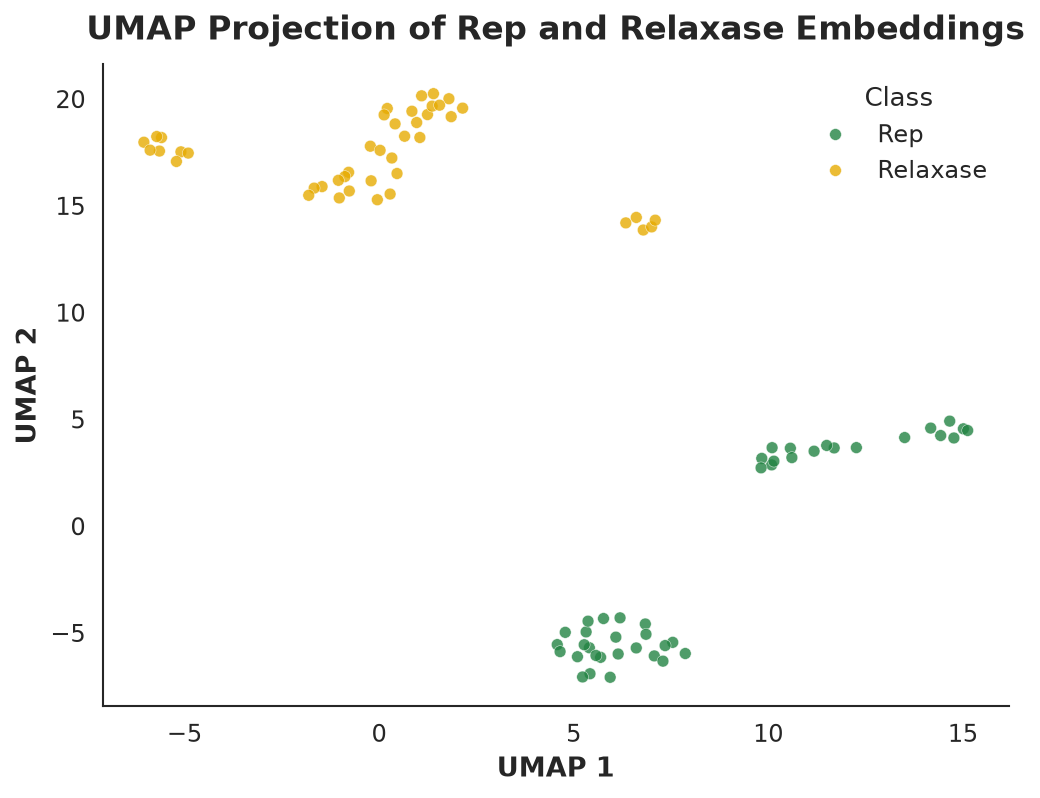

In [22]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from umap import UMAP
import torch

X_rep = torch.load("../data/embeddings/ori_predictor_combined/X_val_rep.pt")
X_relax = torch.load("../data/embeddings/ori_predictor_combined/X_val_relax.pt")

# Convert tensors to NumPy arrays
X_rep = X_rep.detach().cpu().numpy()
X_relax = X_relax.detach().cpu().numpy()

# Combine embeddings and create class labels
X = np.concatenate([X_rep, X_relax], axis=0)
labels = ["Rep"] * len(X_rep) + ["Relaxase"] * len(X_relax)

# Scale features and reduce dimensions
X_scaled = StandardScaler().fit_transform(X)
embedding = UMAP(n_neighbors=8, min_dist=0.5, random_state=42).fit_transform(X_scaled)

plot_data = pd.DataFrame({
    "UMAP 1": embedding[:, 0],
    "UMAP 2": embedding[:, 1],
    "Class": labels,
})

sns.set_theme(style="white", context="paper", font_scale=1.3)
fig, ax = plt.subplots(figsize=(7, 5.5), dpi=150)

sns.scatterplot(
    data=plot_data,
    x="UMAP 1",
    y="UMAP 2",
    hue="Class",
    hue_order=["Rep", "Relaxase"],
    palette={"Rep": "#238443", "Relaxase": "#E6AB02"},
    s=32,
    alpha=0.8,
    edgecolor="white",
    linewidth=0.25,
    ax=ax,
)

ax.set_title("UMAP Projection of Rep and Relaxase Embeddings", pad=12, fontsize=16)
ax.set_xlabel("UMAP 1", fontsize=13)
ax.set_ylabel("UMAP 2", fontsize=13)
ax.legend(title="Class", frameon=False, loc="best")
sns.despine(ax=ax)

fig.tight_layout()
# fig.savefig("umap_rep_relaxase.pdf", bbox_inches="tight")
# fig.savefig("umap_rep_relaxase.png", dpi=600, bbox_inches="tight")
plt.show()